# 🔬 PharmaDemand — Prophet P80 | Backtest fixo D+15

> [!abstract] Objetivo
> Comparar **Prophet central** com **Prophet P80 (cenário de alta demanda)** **fora do ensemble**, utilizando a **mesma série ATC, datas e horizonte fixo D+15** do notebook `08_Prophet.ipynb`.

- `y_pred` = estimativa central (`yhat`) do Prophet, com truncamento em zero.
- `y_pred_p80` = **percentil 80 das amostras preditivas**, não `yhat_upper`. Com `interval_width=0.8`, o `yhat_upper` corresponde aproximadamente ao **P90**.
- Uma linha por **data-alvo** do teste; a origem é sempre `data_alvo - 15 dias`. Refit até essa origem (rolling-origin) e **nenhum target futuro usado**.
- A métrica principal do cenário P80 é **pinball loss de quantil 0,80 e cobertura empírica**. MAE/RMSE do P80 são descritivos: não é o propósito do quantil minimizar RMSE.
- `cumulative_p80` é o **quantil da soma de trajetórias simuladas D+1..D+15**, não a soma dos P80 diários. Não avaliar esse acumulado como vendas realizadas sem validar a janela completa.

> [!warning] Execução
> São até 176 refits do Prophet (`EVAL_STRIDE=1`). Use `EVAL_STRIDE=15` para verificação rápida, mas para comparar com o experimento original D+15 use **1**. As amostras de incerteza geram variabilidade de Monte Carlo; `random_state` é fixado para reprodutibilidade.

## 0. Dependências

```bash
python -m pip install prophet pandas numpy scikit-learn matplotlib pyarrow
```

Copie `ProphetForecaster_P80.py` para `src/models/` (o arquivo é autocontido e preserva a classe anterior). Se executar no projeto, o notebook localiza `data/features/anomaly_predictions.parquet`. Alternativamente configure o caminho `PARQUET_PATH` abaixo.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd().resolve()
ROOT = next((q for q in [HERE, *HERE.parents] if (q / "src").is_dir()), None)
if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

try:
    from src.models.ProphetForecaster_P80 import ProphetForecasterP80
except ImportError:
    # Alternativa: salvar classe e notebook na mesma pasta
    from ProphetForecaster_P80 import ProphetForecasterP80

PARQUET_PATH = None    # Opcional: r"D:\...\anomaly_predictions.parquet"
if PARQUET_PATH is None:
    candidate_paths = ([ROOT / "data" / "features" / "anomaly_predictions.parquet"]
                       if ROOT is not None else []) + [
        HERE / "anomaly_predictions.parquet",
        HERE / "anomaly_predictions(3).parquet",
        HERE.parent / "data" / "features" / "anomaly_predictions.parquet",
    ]
    selected = next((q for q in candidate_paths if q.exists()), None)
    if selected is None:
        raise FileNotFoundError("Defina PARQUET_PATH para o Parquet do PharmaDemand.")
else:
    selected = Path(PARQUET_PATH)

OUTPUT_DIR = (ROOT / "models" / "baseline" if ROOT else HERE / "results_prophet_p80")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", selected, " | Saída:", OUTPUT_DIR)

Importing plotly failed. Interactive plots will not work.


Dataset: D:\PROJETOS\git_repo\PharmaDemand-ml\data\features\anomaly_predictions.parquet  | Saída: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline


## 1. Dados e protocolo temporal do notebook original

A série é `quantity` na categoria ATC correspondente ao arquivo. A filtragem é feita primeiro por `horizon_days=15` e `split=train/test`. Não agregue dados de categorias distintas.

In [2]:
DATE, TARGET, HORIZON = "date", "quantity", 15
ATC_COL, ATC_VALUE = None, None  # Informar se o parquet tiver várias ATCs
EVAL_STRIDE = 1              # 1 = reproduzir 176 origens do notebook anterior
P80, N_SAMPLES, RANDOM_STATE = 0.80, 1000, 3
RUN_GRIDSEARCH = False       # False = reutiliza os parâmetros já encontrados no SEU notebook
BEST_PARAMS_PREVIOUS_RUN = {
    "model__changepoint_prior_scale": 0.01,
    "model__seasonality_mode": "additive",
    "model__seasonality_prior_scale": 1.0,
}

raw = pd.read_parquet(selected)
if ATC_COL is not None:
    if ATC_COL not in raw.columns or ATC_VALUE is None:
        raise ValueError("Defina uma ATC existente e seu valor.")
    raw = raw.loc[raw[ATC_COL].astype(str).eq(str(ATC_VALUE))].copy()

required = {DATE, TARGET, "split", "horizon_days"}
if not required.issubset(raw.columns):
    raise ValueError(f"Parquet sem colunas: {sorted(required - set(raw.columns))}")
raw[DATE] = pd.to_datetime(raw[DATE], errors="raise").dt.normalize()
raw[TARGET] = pd.to_numeric(raw[TARGET], errors="raise")
filtered = raw.loc[raw["horizon_days"].eq(HORIZON)]
train = filtered.loc[filtered["split"].eq("train"), [DATE, TARGET]].copy().sort_values(DATE).reset_index(drop=True)
test = filtered.loc[filtered["split"].eq("test"), [DATE, TARGET]].copy().sort_values(DATE).reset_index(drop=True)
for name, frame in [("train", train), ("test", test)]:
    if frame.empty or frame[DATE].duplicated().any():
        raise ValueError(f"{name}: série vazia ou datas duplicadas; verifique filtro ATC.")
    if frame[[DATE, TARGET]].isna().any().any() or not np.isfinite(frame[TARGET]).all():
        raise ValueError(f"{name}: dados não finitos/nulos.")
if train[DATE].max() >= test[DATE].min():
    raise ValueError("Treino e teste se sobrepõem.")
print("Treino:", len(train), train[DATE].min().date(), "a", train[DATE].max().date())
print("Teste:", len(test), test[DATE].min().date(), "a", test[DATE].max().date())

Treino: 1849 2014-03-17 a 2019-04-08
Teste: 176 2019-04-16 a 2019-10-08


## 2. Recuperação de datas reais na lacuna treino/teste

No notebook original há sete datas entre o final do treino (08/04/2019) e o início do teste (16/04/2019). Este trecho recupera valores reais existentes no próprio Parquet, mas **não inventa zeros** e **não usa observações além da origem de previsão durante o ajuste**.

In [3]:
def assert_regular(frame):
    times = pd.DatetimeIndex(frame[DATE]).sort_values()
    if times.has_duplicates:
        raise ValueError("Datas duplicadas.")
    missing = pd.date_range(times.min(), times.max(), freq="D").difference(times)
    if len(missing):
        raise ValueError(f"Série irregular; {len(missing)} dias ausentes. Ex: {list(missing[:5].date)}")

assert_regular(train)
assert_regular(test)
bridge_dates = pd.date_range(train[DATE].max() + pd.Timedelta(days=1),
                             test[DATE].min() - pd.Timedelta(days=1), freq="D")
if len(bridge_dates):
    observations = raw.loc[raw[DATE].isin(bridge_dates), [DATE, TARGET]].copy()
    counts = observations.groupby(DATE)[TARGET].nunique(dropna=False)
    if (counts != 1).any():
        raise ValueError("Os valores da lacuna conflitam entre horizontes. Use o df_salesdaily da mesma ATC.")
    bridge = observations.drop_duplicates(DATE).sort_values(DATE).reset_index(drop=True)
    remaining = bridge_dates.difference(pd.DatetimeIndex(bridge[DATE]))
    if len(remaining):
        raise ValueError(f"Faltam {len(remaining)} dias observados: {list(remaining[:5].date)}")
else:
    bridge = pd.DataFrame(columns=[DATE, TARGET])
observed = pd.concat([train, bridge, test], ignore_index=True).sort_values(DATE).reset_index(drop=True)
assert_regular(observed)
print(f"Lacuna preenchida somente com valores OBSERVADOS: {len(bridge)} dias")

Lacuna preenchida somente com valores OBSERVADOS: 7 dias


C:\Users\AlexK\AppData\Local\Temp\ipykernel_25108\3937391051.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  bridge_dates = pd.date_range(train[DATE].max() + pd.Timedelta(days=1),
C:\Users\AlexK\AppData\Local\Temp\ipykernel_25108\3937391051.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  test[DATE].min() - pd.Timedelta(days=1), freq="D")


## 3. Hiperparâmetros — reutilizar GridSearch do treino

O notebook enviado já selecionou `changepoint_prior_scale=0.01`, `seasonality_mode='additive'`, `seasonality_prior_scale=1.0` por validação expansiva **D+1..D+15**. Reutilizamos essa seleção para avaliar o quantil sem **otimizar no teste**. Marque `RUN_GRIDSEARCH=True` se sua base tiver mudado.

In [4]:
model = ProphetForecasterP80(
    target_col=TARGET,
    model_dir=str(OUTPUT_DIR),
    date_col=DATE,
    series_col=None,
    forecast_horizon=HORIZON,
    n_splits=3,
    scoring="neg_root_mean_squared_error",
    clip_nonnegative=True,
)
if RUN_GRIDSEARCH:
    grid = {
        "model__changepoint_prior_scale": [0.01, 0.05, 0.1],
        "model__seasonality_prior_scale": [1.0, 5.0],
        "model__seasonality_mode": ["additive", "multiplicative"],
    }
    search = model.gridSearchFind(train, param_grid=grid)
    print("GridSearch apenas no treino:", search.best_params_)
else:
    model.best_params = dict(BEST_PARAMS_PREVIOUS_RUN)
    print("Reutilizando parâmetros da execução original:", model.best_params)
model.fit_with_best_params(train)

Reutilizando parâmetros da execução original: {'model__changepoint_prior_scale': 0.01, 'model__seasonality_mode': 'additive', 'model__seasonality_prior_scale': 1.0}


d:\PROJETOS\git_repo\PharmaDemand-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
09:25:28 - cmdstanpy - INFO - Chain [1] start processing
09:25:29 - cmdstanpy - INFO - Chain [1] done processing


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,changepoint_prior_scale,0.01
,seasonality_prior_scale,1.0
,date_col,'date'
,series_col,None
,horizon,15
,clip_nonnegative,True
,seasonality_mode,'additive'


## 4. 🔎 Backtest **estritamente D+15** com P80

Cada linha de saída corresponde ao **15º dia à frente de uma origem distinta**. Para o alvo 16/04/2019, por exemplo, a origem é 01/04/2019; somente o histórico até 01/04/2019 pode ser usado para o ajuste.

In [5]:
predictions = model.backtest_p80_fixed_h(
    complete_history=observed,
    evaluation_days=test,
    horizon=HORIZON,
    stride=EVAL_STRIDE,
    quantile=P80,
    n_samples=N_SAMPLES,
    random_state=RANDOM_STATE,
)
metrics = model.evaluate_scenarios(predictions, target_col=TARGET, quantile=P80)
print("Previsões D+15:", len(predictions))
display(predictions.head(10))
display(metrics.round(4))
print("Cobertura esperada P80: 80% (se modelo probabilístico calibrado)")

09:25:43 - cmdstanpy - INFO - Chain [1] start processing
09:25:43 - cmdstanpy - INFO - Chain [1] done processing
09:25:44 - cmdstanpy - INFO - Chain [1] start processing
09:25:44 - cmdstanpy - INFO - Chain [1] done processing
09:25:44 - cmdstanpy - INFO - Chain [1] start processing
09:25:44 - cmdstanpy - INFO - Chain [1] done processing
09:25:44 - cmdstanpy - INFO - Chain [1] start processing
09:25:44 - cmdstanpy - INFO - Chain [1] done processing
09:25:45 - cmdstanpy - INFO - Chain [1] start processing
09:25:45 - cmdstanpy - INFO - Chain [1] done processing
09:25:45 - cmdstanpy - INFO - Chain [1] start processing
09:25:45 - cmdstanpy - INFO - Chain [1] done processing
09:25:45 - cmdstanpy - INFO - Chain [1] start processing
09:25:45 - cmdstanpy - INFO - Chain [1] done processing
09:25:46 - cmdstanpy - INFO - Chain [1] start processing
09:25:46 - cmdstanpy - INFO - Chain [1] done processing
09:25:46 - cmdstanpy - INFO - Chain [1] start processing
09:25:46 - cmdstanpy - INFO - Chain [1]

Previsões D+15: 176


,date,horizon_step,y_pred,y_pred_p10,y_pred_p50,y_pred_p80,y_pred_p90,cumulative_center,cumulative_p80,quantity,forecast_origin
0,2019-04-16,15,25.197074,10.769321,25.867892,35.696472,40.819404,410.397133,451.841740,27.200000,2019-04-01
1,2019-04-17,15,24.859630,9.500807,24.337236,34.454670,39.523870,408.847279,446.841841,13.500000,2019-04-02
2,2019-04-18,15,25.512743,9.605338,25.298061,35.199031,41.147780,405.669404,444.434754,21.166667,2019-04-03
3,2019-04-19,15,25.087499,9.943763,24.256405,35.139048,40.259925,401.910022,443.312109,25.000000,2019-04-04
4,2019-04-20,15,31.393930,15.965960,31.588747,41.180543,46.626917,418.097020,455.202459,22.400000,2019-04-05
5,2019-04-21,15,31.790292,15.452643,31.357358,40.784642,45.915732,412.860647,448.594620,21.000000,2019-04-06
6,2019-04-22,15,26.679912,11.218504,26.903576,36.816447,42.143493,404.001425,447.812819,51.000000,2019-04-07
7,2019-04-23,15,25.056902,9.455236,24.595802,34.853213,41.311676,400.254303,438.541836,18.400000,2019-04-08
8,2019-04-24,15,24.161716,8.642450,23.896243,33.658746,38.925322,392.408830,430.164183,39.100000,2019-04-09
9,2019-04-25,15,25.109069,8.897702,24.865973,34.734764,39.976605,396.056465,432.252835,15.000000,2019-04-10


,cenario,mae,rmse,r2,wape_pct,bias,pinball_p80,coverage_pct,n_predictions
0,Prophet central,6.8383,8.6277,0.3612,29.2127,0.6372,3.228,58.5227,176
1,Prophet P80,12.0699,13.5926,-0.5855,51.5617,10.5666,2.865,88.6364,176


Cobertura esperada P80: 80% (se modelo probabilístico calibrado)


## 5. 📈 Gráficos: demanda real, Prophet central e P80

O P80 serve para estimar um cenário de **demanda elevada**. A curva P80 pode ter RMSE superior à central; essa não é uma evidência de mau funcionamento do quantil.

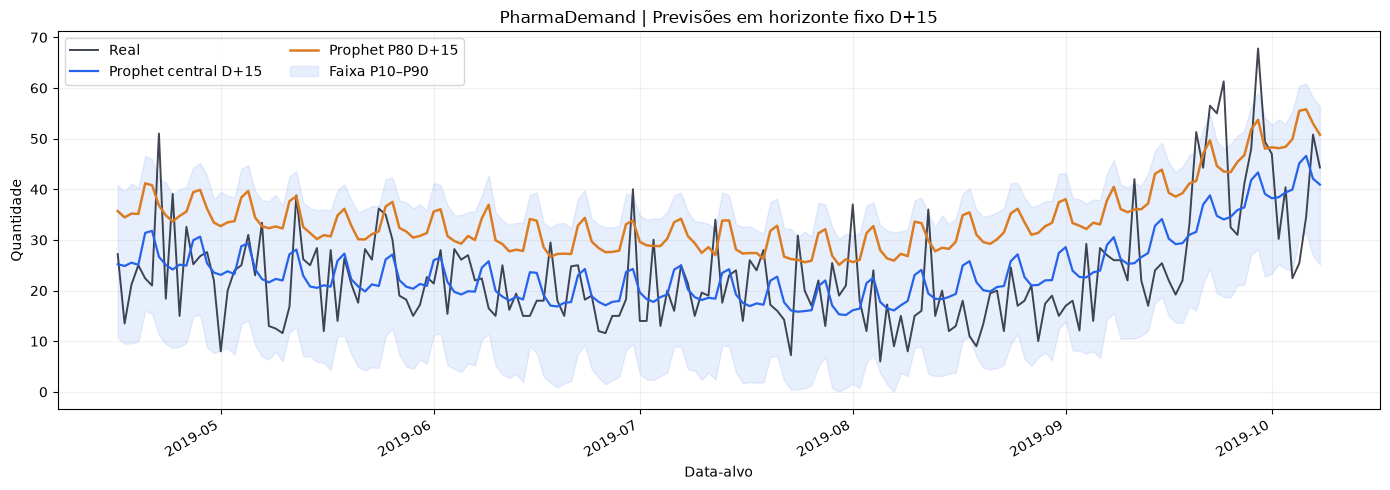

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(predictions[DATE], predictions[TARGET], label="Real", color="#111827", lw=1.4, alpha=.8)
ax.plot(predictions[DATE], predictions["y_pred"], label="Prophet central D+15", color="#2563eb", lw=1.6)
ax.plot(predictions[DATE], predictions["y_pred_p80"], label="Prophet P80 D+15", color="#db7c22", lw=1.8)
ax.fill_between(predictions[DATE], predictions["y_pred_p10"], predictions["y_pred_p90"],
                color="#2563eb", alpha=.10, label="Faixa P10–P90")
ax.set(title="PharmaDemand | Previsões em horizonte fixo D+15", xlabel="Data-alvo", ylabel="Quantidade")
ax.grid(alpha=.18); ax.legend(ncol=2); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 6. 🎯 Avaliação probabilística — cobertura e pinball loss

A cobertura do P80 é a fração de dias cujo **real ficou menor ou igual à previsão P80**. Uma cobertura próxima de 80% sugere calibração desse quantil, mas não a comprova: o holdout é finito e suas origens diárias são sobrepostas. Use **pinball loss** e testes temporais adicionais para decidir se esse cenário é confiável.

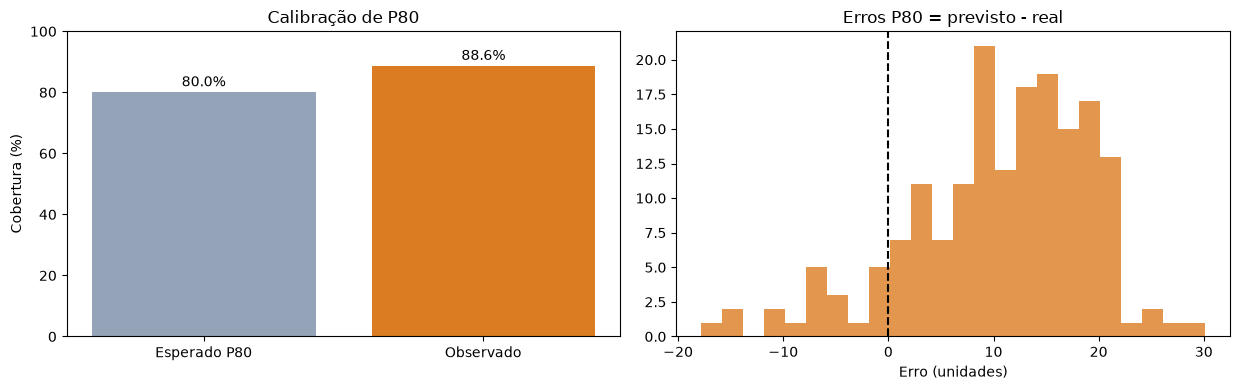

Cobertura=88.64% | Pinball P80=2.8650 | n=176


In [7]:
coverage = float((predictions[TARGET] <= predictions["y_pred_p80"]).mean()) * 100
pinball = float(metrics.loc[metrics["cenario"].eq("Prophet P80"), "pinball_p80"].iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
axes[0].bar(["Esperado P80", "Observado"], [80, coverage], color=["#94a3b8", "#db7c22"])
axes[0].set_ylim(0, 100); axes[0].set_ylabel("Cobertura (%)"); axes[0].set_title("Calibração de P80")
for i, v in enumerate([80, coverage]): axes[0].text(i, v + 2, f"{v:.1f}%", ha="center")
axes[1].hist(predictions["y_pred_p80"] - predictions[TARGET], bins=24, color="#db7c22", alpha=.8)
axes[1].axvline(0, color="black", ls="--")
axes[1].set_title("Erros P80 = previsto - real"); axes[1].set_xlabel("Erro (unidades)")
plt.tight_layout(); plt.show()
print(f"Cobertura={coverage:.2f}% | Pinball P80={pinball:.4f} | n={len(predictions)}")

## 7. 📦 Cenário acumulado de 15 dias

Uma previsão P80 **acumulada D+1..D+15** deve ser obtida somando cada trajetória simulada e depois calculando o quantil 0,80. No resultado do backtest, as colunas `cumulative_center` e `cumulative_p80` são calculadas corretamente **para a origem de cada linha**. Os totais de origens consecutivas se sobrepõem: não os some entre linhas.

In [ ]:
recent = predictions.tail(8)[[DATE, "forecast_origin", "y_pred", "y_pred_p80", "cumulative_center", "cumulative_p80"]].copy()
recent["delta_pct_total"] = 100 * (recent["cumulative_p80"] / recent["cumulative_center"] - 1)
display(recent.round(2))

## 8. 🗂️ Salvar resultados para Streamlit / Looker / documentação

O Prophet não entra no metamodelo Ridge: estes CSVs servem à comparação de cenários. Para contrastar com o ensemble, faça join de **ATC, data-alvo, origem e horizonte**. Não compare resultados D+1..D+15 com resultados estritos D+15.

In [ ]:
pred_file = OUTPUT_DIR / f"prophet_p80_predictions_fixed_h{HORIZON}.csv"
metrics_file = OUTPUT_DIR / f"prophet_p80_metrics_fixed_h{HORIZON}.csv"
params_file = OUTPUT_DIR / f"prophet_p80_best_params_h{HORIZON}.json"
predictions.to_csv(pred_file, index=False, encoding="utf-8-sig")
metrics.to_csv(metrics_file, index=False, encoding="utf-8-sig")
params_file.write_text(__import__("json").dumps({
    "best_params": model.best_params,
    "selection_data": "train_only",
    "selection_metric": "RMSE em blocos D+1..D+15",
    "horizon": HORIZON, "quantile": P80,
    "uncertainty_samples": N_SAMPLES,
    "random_state": RANDOM_STATE,
    "evaluation_stride": EVAL_STRIDE,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Previsões:", pred_file)
print("Métricas:", metrics_file)
print("Parâmetros:", params_file)

## 9. 🧠 Como interpretar para o seu portfólio

1. **O ensemble continua sendo o forecast operacional central**, avaliado com MAE/RMSE/WAPE/Bias.
2. **Prophet central** permanece como benchmark externo, sem entrar no Ridge.
3. **Prophet P80** pode atuar como cenário de **pressão de demanda e estoque**, desde que a cobertura empírica e o pinball loss sustentem seu uso.
4. **P80 não é garantia de estoque seguro**: lead times e custos de ruptura exigem políticas próprias, e o Prophet assume dinâmica futura de tendências semelhante à observada.
5. **Comparação justa**: mesma ATC, mesmas datas, mesmas origens e horizonte D+15.

> [!note] Resultado anterior conhecido (Prophet central)
> Seu `08_Prophet.ipynb` já registrou no holdout: **MAE 6,9651 • RMSE 9,0123 • R² 0,3374 • WAPE 30,1046% • bias 0,0405** para **176** origens D+15. O novo resultado deve reproduzir valores próximos para `y_pred` (com os mesmos parâmetros e dados). Os números do P80 só aparecem após **execução real deste notebook**.

### 📚 Referências
- [Prophet — intervalos de incerteza](https://facebook.github.io/prophet/docs/uncertainty_intervals.html)
- [Prophet — diagnóstico](https://facebook.github.io/prophet/docs/diagnostics.html)